# 05. SHAP Interpretation

Goal: explain why customers churn, both globally and within each segment, using SHAP.

This answers RQ3, which asks which features drive churn within each segment, and provides the actionable business insight of the project.

Outputs:

* ../results/figures/shap_global.png
* ../results/tables/shap_per_segment.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, joblib
warnings.filterwarnings('ignore')

import shap
import xgboost as xgb
from imblearn.over_sampling import SMOTE

SEED = 42
np.random.seed(SEED)

data = joblib.load('../data/processed/train_test.pkl')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
seg_test = data['seg_test']
print('Loaded the split. Test size:', len(X_test))

Loaded the split. Test size: 1407


## 1. Train the model to explain

We train one unified XGBoost with the same settings as notebook 03 and explain it with the SHAP TreeExplainer, which is fast and exact for tree models.

In [2]:
X_tr_sm, y_tr_sm = SMOTE(random_state=SEED).fit_resample(X_train, y_train)

model = xgb.XGBClassifier(n_estimators=100, random_state=SEED,
                          eval_metric='logloss', verbosity=0)
model.fit(X_tr_sm, y_tr_sm)

explainer = shap.TreeExplainer(model)
print('Explainer ready')

Explainer ready


## 2. Global feature importance

We sample 300 test customers, since SHAP is expensive to compute, and average the absolute SHAP values to rank the overall churn drivers.

In [3]:
X_sample = X_test.sample(n=300, random_state=SEED)
shap_values = explainer.shap_values(X_sample)

global_imp = (pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns)
                .sort_values(ascending=False))
print('Top 10 global churn drivers:')
print(global_imp.head(10).round(4))

Top 10 global churn drivers:
tenure                            0.8802
Contract_Two year                 0.6343
PaymentMethod_Electronic check    0.4820
TotalCharges                      0.3763
MonthlyCharges                    0.3660
InternetService_Fiber optic       0.3396
Contract_One year                 0.3102
MultipleLines_Yes                 0.1704
OnlineSecurity_Yes                0.1573
PaperlessBilling_Yes              0.1512
dtype: float32


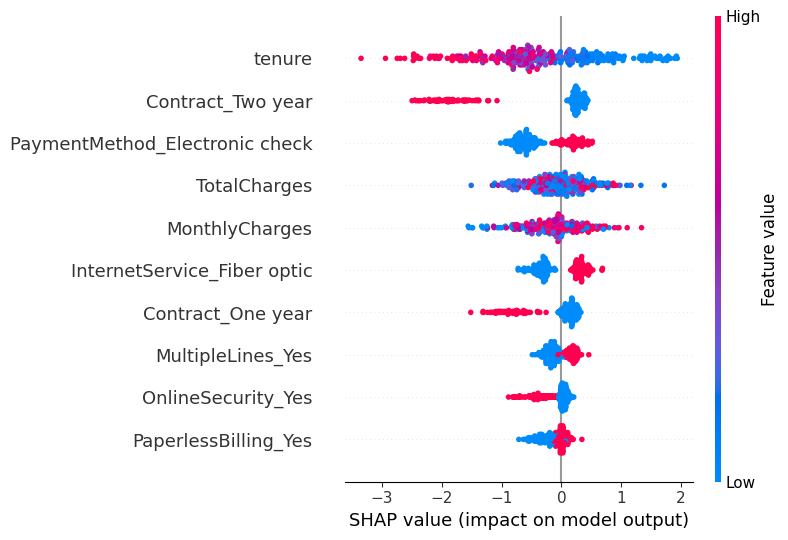

In [4]:
shap.summary_plot(shap_values, X_sample, max_display=10, show=False)
plt.tight_layout()
plt.savefig('../results/figures/shap_global.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Churn drivers within each segment

This is the key finding. We compute the top drivers within each segment separately. If the top drivers differ across segments, that is direct evidence that a single model masks segment level behaviour, which is the core argument of the project.

In [5]:
rows = []
for seg in sorted(seg_test.unique()):
    mask = (seg_test == seg).values
    if mask.sum() < 20:
        print(f'Segment {seg}: too small for stable SHAP')
        continue
    Xs = X_test[mask].sample(n=min(150, mask.sum()), random_state=SEED)
    sv = explainer.shap_values(Xs)
    imp = (pd.Series(np.abs(sv).mean(axis=0), index=X_test.columns)
             .sort_values(ascending=False).head(3))
    top3 = ', '.join(imp.index)
    rows.append([seg, mask.sum(), y_test[mask].mean(), top3])
    print(f'Segment {seg} (churn {y_test[mask].mean():.0%}): {top3}')

per_seg = pd.DataFrame(rows, columns=['Segment','n_test','ChurnRate','Top3_Drivers'])

Segment 0 (churn 15%): tenure, Contract_Two year, PaymentMethod_Electronic check
Segment 1 (churn 24%): tenure, PaymentMethod_Electronic check, Contract_Two year
Segment 2 (churn 49%): tenure, PaymentMethod_Electronic check, InternetService_Fiber optic
Segment 3 (churn 2%): tenure, Contract_Two year, PaymentMethod_Electronic check


## 4. Save

In [6]:
per_seg.to_csv('../results/tables/shap_per_segment.csv', index=False)
print('Saved: shap_global.png, shap_per_segment.csv')
print()
print('Analysis complete. All results are in ../results/ for the report.')

Saved: shap_global.png, shap_per_segment.csv

Analysis complete. All results are in ../results/ for the report.
